# AlphaEvolve + **Qwen3-VL-2B-Instruct** on **PlotQA** — Google Colab

Runs **AlphaEvolve** (`evolve_plotqa.py`) with `evaluate_plotqa.py` on **jrc/cleaned-plotqa-v2 train**.

**Optional uploads:** After the project folder exists, you may upload your own `evolve_plotqa.py` and/or `evolved_plotqa.py` into `evolving-vlm-inference-main/` (Colab sidebar) to replace the repo copies before running evolution or the post-evolution benchmark.

**Colab:** **Runtime → GPU**. **Secrets:** `HF_TOKEN`, `GEMINI_API_KEY`.

**Before/after demo:** Same `SAMPLE` chart — EXAMPLE cells use `seed_instruct.py` then `evolved_plotqa.py`; the visual demo scans for a contrastive hit (seed wrong → evolved right).

**Project path:** `/content/evolving-vlm-325/evolving-vlm-inference-main` (upload or `GIT_REPO_URL`).


In [ ]:
import os
from pathlib import Path

PROJECT_ROOT = Path(os.environ.get("COLAB_PROJECT_ROOT", "/content/evolving-vlm-325/evolving-vlm-inference-main"))
GIT_REPO_URL = os.environ.get("GIT_REPO_URL", "")

NUM_GENERATIONS = int(os.environ.get("NUM_GENERATIONS", "3"))
POPULATION_SIZE = int(os.environ.get("POPULATION_SIZE", "6"))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("NUM_GENERATIONS:", NUM_GENERATIONS, "POPULATION_SIZE:", POPULATION_SIZE)



PROJECT_ROOT: /content/evolving-vlm-325/evolving-vlm-inference-main
NUM_GENERATIONS: 3 POPULATION_SIZE: 6


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/projectFiles.zip")  # change if your file name differs
out_dir = Path("/content")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(out_dir)

# If the zip already contains a top-level folder "evolving-vlm-inference-main", you're done.
# If it extracted into a wrong name, rename so this path exists:
assert (out_dir / "evolving-vlm-325/evolving-vlm-inference-main").is_dir(), list(out_dir.iterdir())



In [ ]:
%%capture
!pip install -q "transformers>=4.37.0" qwen-vl-utils torch torchvision pillow accelerate google-generativeai bitsandbytes datasets huggingface_hub



In [ ]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU. In Colab: Runtime → Change runtime type → GPU (e.g. T4), then re-run."
    )
print("GPU:", torch.cuda.get_device_name(0))



GPU: NVIDIA A100-SXM4-40GB


In [ ]:
import os, shutil, subprocess
from pathlib import Path

if GIT_REPO_URL:
    if PROJECT_ROOT.exists():
        shutil.rmtree(PROJECT_ROOT)
    subprocess.run(["git", "clone", "--depth", "1", GIT_REPO_URL, str(PROJECT_ROOT)], check=True)
elif not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"{PROJECT_ROOT} not found. Upload repo to /content/evolving-vlm-325/evolving-vlm-inference-main or set GIT_REPO_URL."
    )

os.chdir(PROJECT_ROOT)
print("cwd:", os.getcwd())



cwd: /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
# Optional: upload evolve_plotqa.py / evolved_plotqa.py into PROJECT_ROOT (Colab sidebar).
print("Optional: upload evolve_plotqa.py or evolved_plotqa.py into", PROJECT_ROOT)



Optional: upload evolve_plotqa.py or evolved_plotqa.py into /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
import os
from google.colab import userdata

try:
    os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
except Exception:
    from huggingface_hub import login
    login()

try:
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
except Exception:
    pass

if not os.environ.get("GEMINI_API_KEY"):
    from getpass import getpass
    os.environ["GEMINI_API_KEY"] = getpass("Enter GEMINI_API_KEY: ")

assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is required."



/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Enter GEMINI_API_KEY: ··········


In [ ]:
import os
import sys
import importlib.util
from pathlib import Path

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))


def load_module(name: str, path: Path):
    spec = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(m)
    return m


from datasets import load_dataset

_sample_dir = Path("/tmp/plotqa_colab_sample")
_sample_dir.mkdir(parents=True, exist_ok=True)
_ds = load_dataset("jrc/cleaned-plotqa-v2", split="train")
_row = _ds[0]
_img = _row["image"]
_p = _sample_dir / "sample0.png"
if hasattr(_img, "convert"):
    _img.convert("RGB").save(_p)
_q = (_row.get("user") or "").strip().split("\n", 1)[0].strip()
_gold = str(_row.get("assistant") or "").strip()
SAMPLE = {"image_path": str(_p), "question": _q, "qid": None, "gold": _gold}
print("Sample:", SAMPLE["question"][:120], "Gold:", SAMPLE["gold"])



README.md:   0%|          | 0.00/363 [00:00<?, ?B/s]

data/train-00000-of-00015.parquet:   0%|          | 0.00/8.14M [00:00<?, ?B/s]

data/train-00001-of-00015.parquet:   0%|          | 0.00/7.85M [00:00<?, ?B/s]

data/train-00002-of-00015.parquet:   0%|          | 0.00/8.19M [00:00<?, ?B/s]

data/train-00003-of-00015.parquet:   0%|          | 0.00/8.05M [00:00<?, ?B/s]

...

data/train-00012-of-00015.parquet:   0%|          | 0.00/7.63M [00:00<?, ?B/s]

data/train-00013-of-00015.parquet:   0%|          | 0.00/8.62M [00:00<?, ?B/s]

data/train-00014-of-00015.parquet:   0%|          | 0.00/8.33M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/199293 [00:00<?, ? examples/s]

Sample: Are the number of bars on each tick of the Y-axis equal? Gold: Yes.


In [ ]:
initial = load_module("alphaevolve_seed_colab", PROJECT_ROOT / "seed_instruct.py")
before_pred = initial.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — generation 0 (PlotQA) ===")
print("Prediction:", before_pred)
print("Gold      :", SAMPLE["gold"])


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/4.26G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


=== EXAMPLE — generation 0 (PlotQA) ===
Prediction: Yes, the number of bars on each tick of the Y-axis is equal. For each year (1974 and 2000), there are two bars: one for "Female" (teal) and one for "Male" (dark green). This is consistent across both the 1974 and 2000 rows.
Gold      : Yes.


In [ ]:
from evaluate_plotqa import evaluate

print("=== BENCHMARK — generation 0 ===")
bench_before = evaluate(initial, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_before[k]}")


=== BENCHMARK — generation 0 ===
  desc_accuracy: 0.0
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 970.8808083534241
  avg_time_per_query: 5.056670876840751


In [ ]:
import gc, sys, torch
_mname = "alphaevolve_seed_colab"
if _mname in sys.modules:
    mod = sys.modules.pop(_mname)
    for attr in ("_model", "_processor"):
        if hasattr(mod, attr):
            setattr(mod, attr, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Released generation-0 module.")


Released generation-0 module.


In [ ]:
import evolve_plotqa

evolve_plotqa.NUM_GENERATIONS = NUM_GENERATIONS
evolve_plotqa.POPULATION_SIZE = POPULATION_SIZE
population, history = evolve_plotqa.run_evolution()
print("History entries:", len(history))


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Generations : 25  |  Population : 10
Gemini model: gemini-2.5-flash  (override with GEMINI_MODEL env; 2.0-flash is unavailable for new keys)
Train split : 102 desc + 51 rsn samples
Holdout     : 26 desc + 13 rsn samples
Fitness     : descriptive accuracy (exact-match, train split)
Saves best  : by holdout accuracy (anti-overfitting)
Crossover   : every 5 generations
Seeds       : seed_instruct.py + 0 extra variants  →  evolved_plotqa.py
AlphaEvolve — Qwen/Qwen3-VL-2B-Instruct (PlotQA)

[Gen 0] Evaluating seed: seed_instruct.py


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  Train acc  : 0.0%  |  Holdout acc : 0.0%  |  4.798s/q

  Best gen-0 seed by holdout: 0.0%  (train 0.0%)  → saved to evolved_plotqa.py

[Gen 1/25]
  Parent: 0.0%/0.0% acc (gen 0)
  Evaluating child...


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

...

  Child : train=15.7%  holdout=0.0%  0.402s/q
  Best by holdout : 0.0%  (train 41.8%)  → saved to evolved_plotqa.py

[Gen 24/25]
  Parent: 24.8%/0.0% acc (gen 15)
  Evaluating child...


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  Child : train=26.1%  holdout=0.0%  0.397s/q
  Best by holdout : 0.0%  (train 41.8%)  → saved to evolved_plotqa.py

[Gen 25/25]
  [CROSSOVER] A: 24.8%/0.0%  B: 41.2%/0.0%  (train/holdout)
  Evaluating child...


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  Child : train=41.2%  holdout=0.0%  0.404s/q
  Best by holdout : 0.0%  (train 41.8%)  → saved to evolved_plotqa.py

Evolution complete!
  Best by train   : 41.8%  holdout=0.0%
  Best by holdout : 0.0%  train=41.8%  ← saved to disk
  Best speed      : 41.2%  (0.402s/q)
  Best overall    : 41.8%  score=0.3116
  Log             : evolution_log_plotqa.json
History entries: 26


In [ ]:
evolved = load_module("evolved_plotqa_colab", PROJECT_ROOT / "evolved_plotqa.py")
after_pred = evolved.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — after AlphaEvolve (PlotQA) ===")
print("Prediction:", after_pred)
print("Gold      :", SAMPLE["gold"])


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

=== EXAMPLE — after AlphaEvolve (PlotQA) ===
Prediction: Yes.
Gold      : Yes.


### Contrastive chart from dataset (unevolved **wrong** → evolved **correct**)

Run this cell **after** evolution. It scans up to `MAX_CONTRASTIVE_SCAN` **seed** failures from **PlotQA**, re-runs **evolved** on each, and shows the **first** chart where the seed misses gold but evolved matches (exact match on plot answers). Displays the figure, question, gold, and both predictions.

If no such example exists in the scan budget, the cell reports that and skips display (no fallback sample).

Scanning up to 120 seed failures on PlotQA …


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

## Contrastive chart from PlotQA

*Unevolved (seed) is wrong; evolved matches gold.*

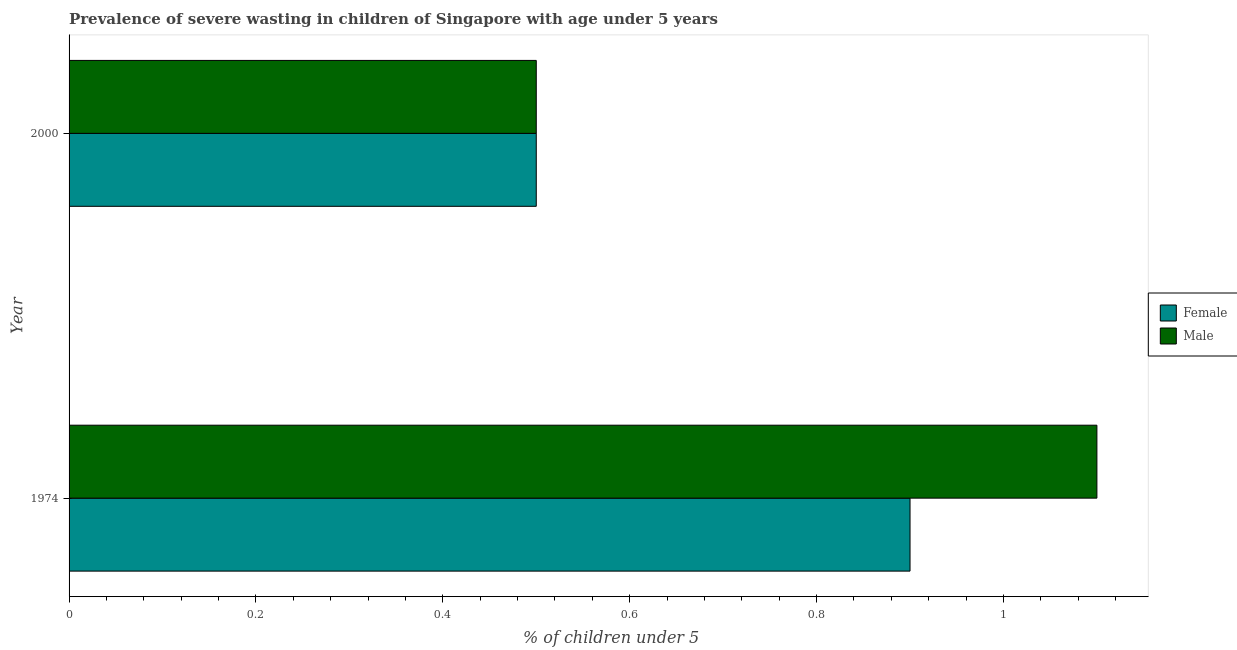

**Question**

Are the number of bars on each tick of the Y-axis equal?

Query key          : pq_0
Gold (correct)     : Yes.
Unevolved (seed)   : Yes, the number of bars on each tick of the Y-axis is equal. For each year (1974 and 2000), there are two bars: one for "Female" (teal) and one for "Male" (dark green). This is consistent across both the 1974 and 2000 rows.   ← WRONG
Evolved            : Yes.   ← CORRECT
Reloaded `evolved` for the benchmark cell below.


In [ ]:
import os
from pathlib import Path
import gc
import sys
import torch
from IPython.display import display, Markdown, Image as IPyImage
from evaluate_plotqa import find_contrastive_plotqa_sample

MAX_CONTRASTIVE_SCAN = int(os.environ.get("MAX_CONTRASTIVE_SCAN", "120"))


def _vram_detach(mod_name: str) -> None:
    if mod_name in sys.modules:
        m = sys.modules.pop(mod_name)
        for attr in ("_model", "_processor"):
            if hasattr(m, attr):
                setattr(m, attr, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


_vram_detach("evolved_plotqa_colab")
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"Scanning up to {MAX_CONTRASTIVE_SCAN} seed failures on PlotQA …")
seed_v = load_module("_contrast_seed", PROJECT_ROOT / "seed_instruct.py")
evo_v = load_module("_contrast_evo", PROJECT_ROOT / "evolved_plotqa.py")
pair = find_contrastive_plotqa_sample(seed_v, evo_v, max_failure_checks=MAX_CONTRASTIVE_SCAN)
_vram_detach("_contrast_seed")
_vram_detach("_contrast_evo")

if pair is None:
    display(Markdown("### No contrastive example found"))
    print(
        f"No chart in the first {MAX_CONTRASTIVE_SCAN} seed failures where "
        "unevolved is wrong AND evolved is correct."
    )
    print("Try increasing MAX_CONTRASTIVE_SCAN or re-running evolution.")
else:
    CONTRASTIVE_SAMPLE = pair
    p = Path(pair["image_path"])
    if not p.is_file():
        raise FileNotFoundError(p)
    display(Markdown("## Contrastive chart from PlotQA"))
    display(Markdown("*Unevolved (seed) is wrong; evolved matches gold.*"))
    display(IPyImage(filename=str(p)))
    q = pair["question"]
    display(Markdown("**Question**"))
    display(Markdown((q[:2000] + "…") if len(q) > 2000 else q))
    print("Query key          :", pair["key"])
    print("Gold (correct)     :", pair["gold"])
    print("Unevolved (seed)   :", pair["seed_response"], "  ← WRONG")
    print("Evolved            :", pair["evolved_response"], "  ← CORRECT")

evolved = load_module("evolved_plotqa_colab", PROJECT_ROOT / "evolved_plotqa.py")
print("Reloaded `evolved` for the benchmark cell below.")



In [ ]:
from evaluate_plotqa import evaluate

print("=== BENCHMARK — after AlphaEvolve ===")
bench_after = evaluate(evolved, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_after[k]}")
print("\n=== SUMMARY (PlotQA: seed → evolved) ===")
print(f"Accuracy: {bench_before['desc_accuracy']:.4f} → {bench_after['desc_accuracy']:.4f}")
print("\n=== SAME-SAMPLE BEFORE / AFTER ===")
try:
    q = SAMPLE["question"]
    print("Question (trim):", (q[:240] + "…") if len(q) > 240 else q)
    print("Gold     :", SAMPLE["gold"])
    print("Seed pred:", before_pred)
    print("Evolved  :", after_pred)
except NameError:
    print("(Re-run the two EXAMPLE cells so `before_pred` and `after_pred` exist.)")


=== BENCHMARK — after AlphaEvolve ===


Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

  desc_accuracy: 0.3333333333333333
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 75.80618214607239
  avg_time_per_query: 0.394823865344127

=== SUMMARY (PlotQA: seed → evolved) ===
Accuracy: 0.0000 → 0.3333

=== SAME-SAMPLE BEFORE / AFTER ===
Question (trim): Are the number of bars on each tick of the Y-axis equal?
Gold     : Yes.
Seed pred: Yes, the number of bars on each tick of the Y-axis is equal. For each year (1974 and 2000), there are two bars: one for "Female" (teal) and one for "Male" (dark green). This is consistent across both the 1974 and 2000 rows.
Evolved  : Yes.
